In [2]:
import sys
sys.path.append("/nas/longleaf/home/meashe/.local/lib/python3.11/site-packages")
import mne
# print(mne.__version__)

# !pip install nilearn
# https://openneuro.org/datasets/ds006036/versions/1.0.6

# !pip install mne autoreject matplotlib numpy pandas python-picard

import mne
import numpy as np
import pandas as pd
from pathlib import Path

# used for fixing errors in transfer from computer to Longleaf
    # print("NumPy:", np.__version__)
    # print("Pandas:", pd.__version__)
    # print("Python:", sys.executable)

# !pip install mne matplotlib

import os

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


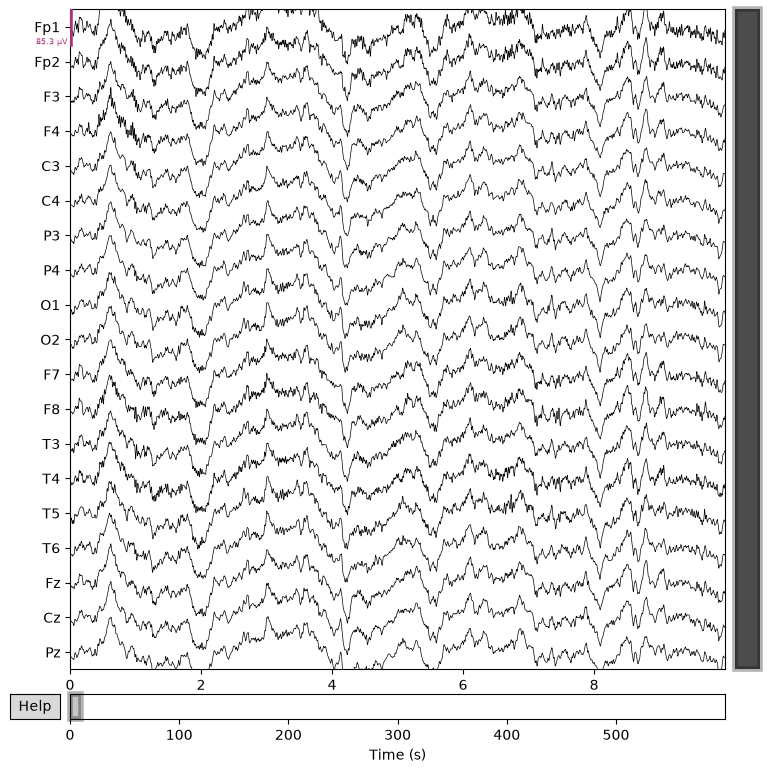

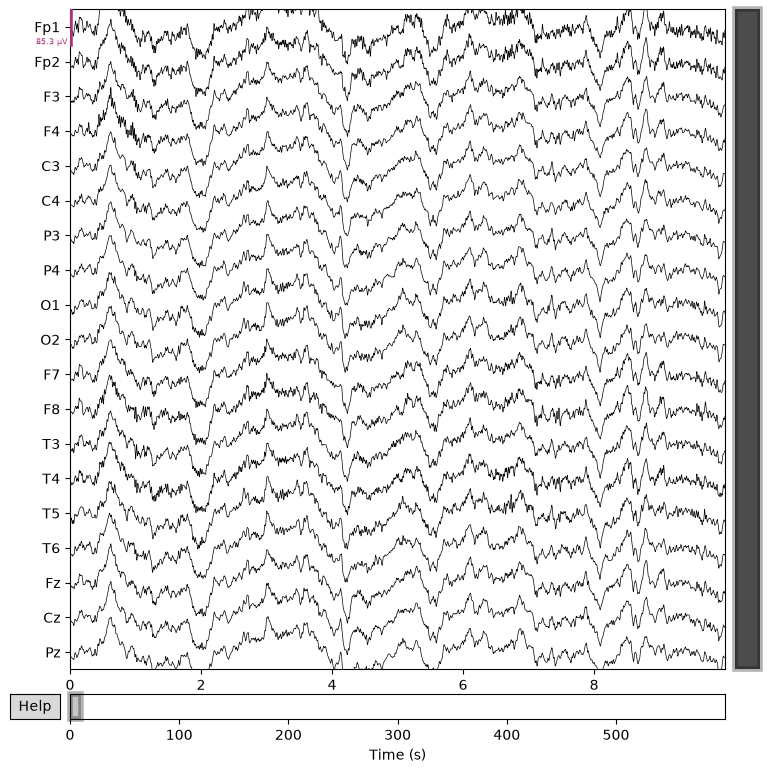

In [17]:
# manually visualizing all preprocessed channels for subject

subject = mne.io.read_raw_eeglab('/hickory/users/m/e/meashe/NSCI270/derivatives/sub-001/eeg/sub-001_task-eyesclosed_eeg.set', preload=True)
# Plot the interactive raw EEG traces
subject.plot(duration=10.0, n_channels=19, scalings='auto')


In [4]:
data_dir = '/hickory/users/m/e/meashe/NSCI270/derivatives'

participants = [
    folder for folder in os.listdir(data_dir)
    if folder.startswith('sub-')
]

print(participants)

['sub-001', 'sub-002', 'sub-003', 'sub-004', 'sub-005', 'sub-006', 'sub-007', 'sub-008', 'sub-009', 'sub-010', 'sub-011', 'sub-012', 'sub-013', 'sub-014', 'sub-015', 'sub-016', 'sub-017', 'sub-018', 'sub-019', 'sub-020', 'sub-021', 'sub-022', 'sub-023', 'sub-025', 'sub-026', 'sub-027', 'sub-028', 'sub-029', 'sub-031', 'sub-032', 'sub-033', 'sub-034', 'sub-035', 'sub-036', 'sub-037', 'sub-038', 'sub-039', 'sub-040', 'sub-041', 'sub-042', 'sub-043', 'sub-044', 'sub-045', 'sub-046', 'sub-047', 'sub-048', 'sub-049', 'sub-050', 'sub-051', 'sub-052', 'sub-053', 'sub-054', 'sub-055', 'sub-056', 'sub-057', 'sub-058', 'sub-059', 'sub-060', 'sub-061', 'sub-062', 'sub-063', 'sub-064', 'sub-065', 'sub-066', 'sub-068', 'sub-069', 'sub-070', 'sub-071', 'sub-072', 'sub-073', 'sub-074', 'sub-075', 'sub-076', 'sub-077', 'sub-078', 'sub-079', 'sub-080', 'sub-081', 'sub-082', 'sub-083', 'sub-084', 'sub-085', 'sub-087', 'sub-088']


In [ ]:
# preprocessing verification: checking for bad channels

def verify_bad_channels(participant):

    eeg_file = os.path.join(
        data_dir,
        participant,
        'eeg',
        f'{participant}_task-eyesclosed_eeg.set'
    )
        
    processed = mne.io.read_raw_eeglab(
        eeg_file,
        preload=True
    )

    # processed.crop(tmin=0, tmax=60).load_data()

    data, times = processed.get_data(return_times=True)
    ch_names = processed.ch_names

    # Calculate standard deviation for each channel
    ch_stds = np.std(data, axis=1)

    # Define a threshold (e.g., 3 standard deviations above the median channel std)
    median_std = np.median(ch_stds)
    std_threshold = 3 * np.mad(ch_stds) if hasattr(np, 'mad') else 3 * np.std(ch_stds)

    # Find channels that are too noisy (high std) or flat (near 0 std)
    noisy_indices = np.where((ch_stds > np.mean(ch_stds) + 2.5 * np.std(ch_stds)) | (ch_stds < 1e-6))[0]
    detected_bads = [ch_names[i] for i in noisy_indices]

    print("Custom detected noisy channels:", detected_bads)
    processed.info["bads"] = detected_bads

    return processed

all_results = {}

for participant in participants:

    print(f'\nChecking {participant}...')

    try:
        processed = verify_bad_channels(participant)

        all_results[participant] = {
            'n_channels': len(processed.ch_names),
            'channel_names': processed.ch_names
        }

    except Exception as e:
        print(f'Error with {participant}: {e}')

In [43]:
# creating epochs (no loop yet, just individual participant)

events = mne.make_fixed_length_events(
    subject,
    id=1,
    duration=2.0
)

event_id = {"rest": 1}

epochs_clean = mne.Epochs(
    subject,
    events,
    event_id=event_id,
    tmin=0,
    tmax=2.0,
    baseline=None,
    preload=True,
    reject_by_annotation=True
)

print(epochs_clean)

Not setting metadata
274 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 274 events and 1001 original time points ...
0 bad epochs dropped
<Epochs | 274 events (all good), 0 – 2 s (baseline off), ~39.8 MiB, data loaded,
 'rest': 274>


For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


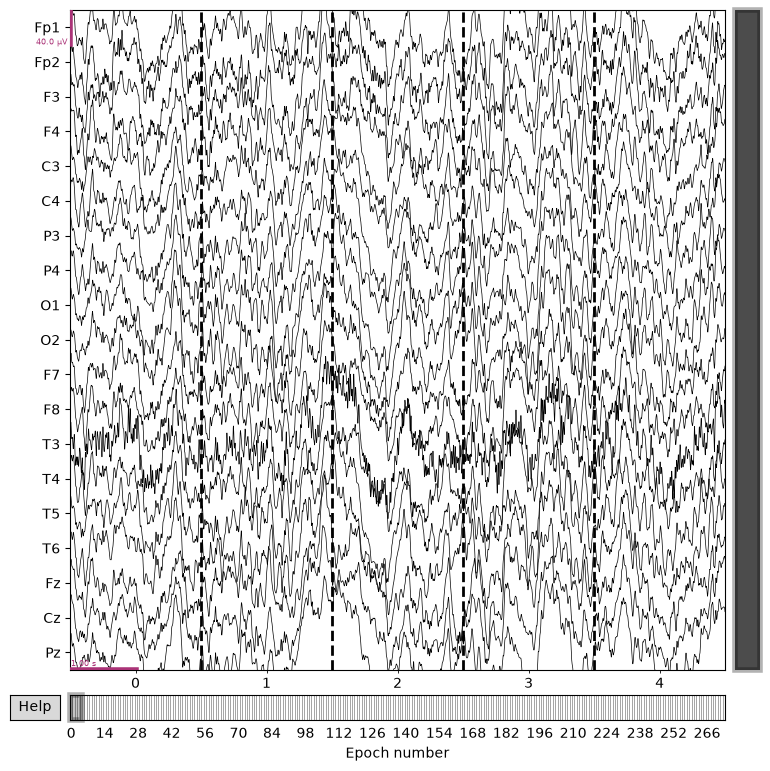

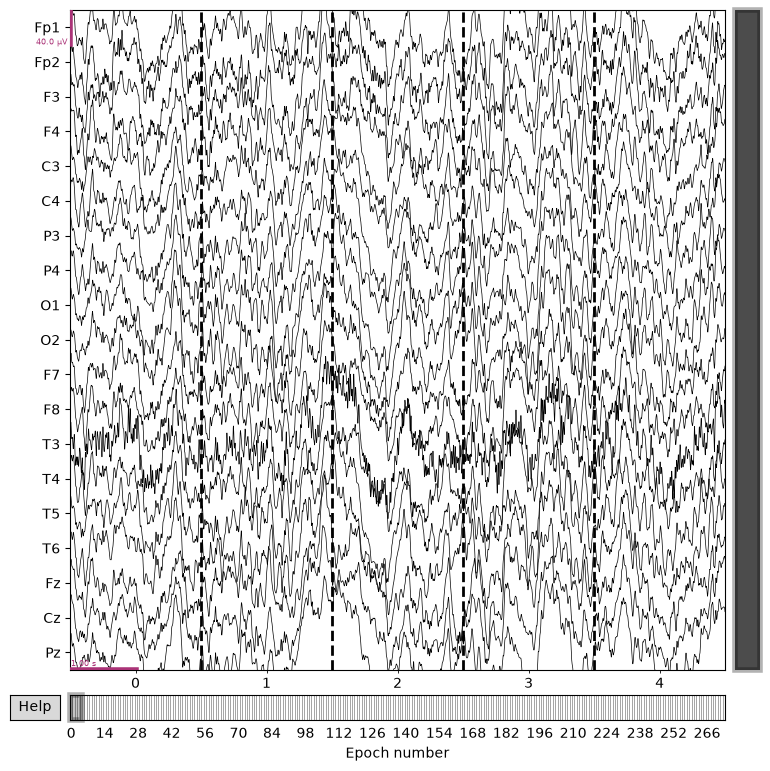

In [44]:
# visualizing epochs

epochs_clean.plot(
    n_epochs=5,
    n_channels=19
)

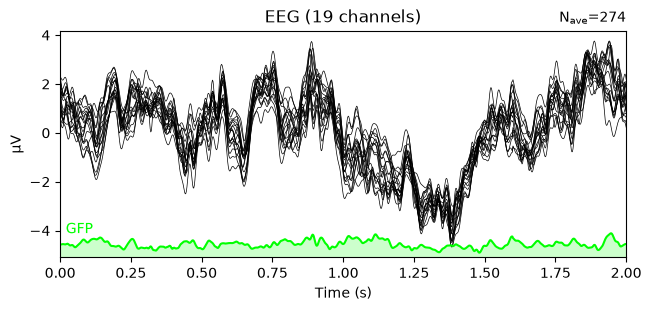

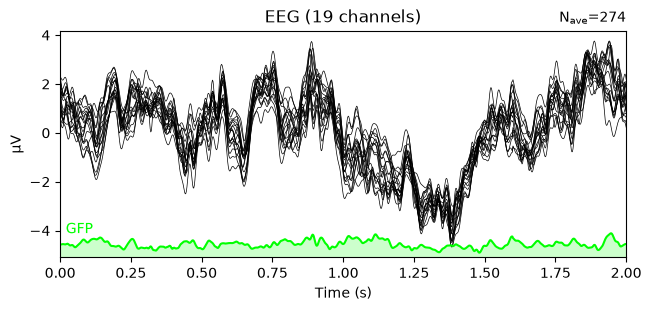

In [45]:
evoked_rest = epochs_clean["rest"].average()

evoked_rest.plot(
    spatial_colors=False,
    gfp=True
)

In [46]:
# 1. Find the EEG channels that are not marked as bad
eeg_picks = mne.pick_types(
    subject.info, 
    eeg=True, 
    exclude="bads"
)

# 2. Calculate PSD using those exact channels
psd = subject.compute_psd(
    method="welch",
    fmin=0.5,
    fmax=40,
    n_fft=2048,
    picks=eeg_picks
)

# 3. Extract data, frequencies, and synchronized channel names
psds = psd.get_data()
freqs = psd.freqs
psd_ch_names = psd.ch_names  # Automatically matches the 30 active channels

print("PSD shape:", psds.shape)

Effective window size : 4.096 (s)
PSD shape: (19, 161)


Plotting power spectral density (dB=True).


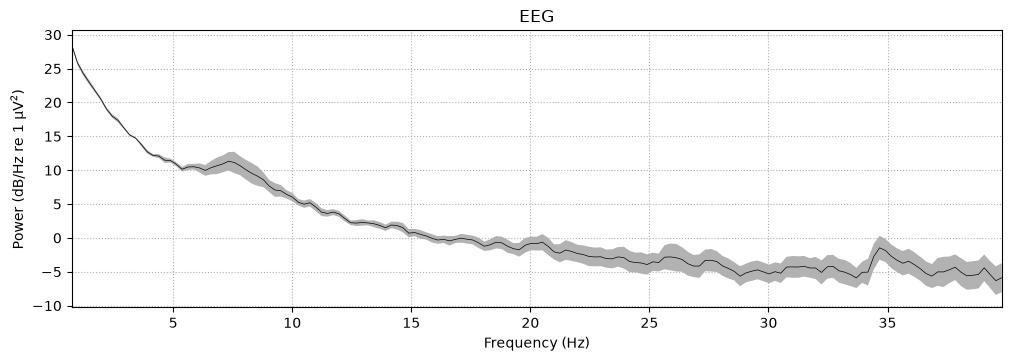

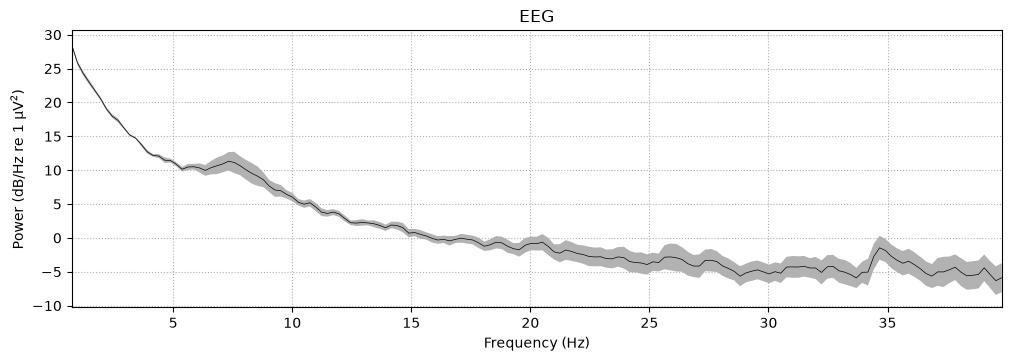

In [47]:
psd.plot(
    average=True,
    picks="eeg"
)

In [48]:
# Print diagnostic information
print(f"PSD data shape: {psds.shape}")
print(f"Channel names count: {len(psd_ch_names)}")
print(f"Excluded bad channels: {subject.info['bads']}")

PSD data shape: (19, 161)
Channel names count: 19
Excluded bad channels: []


In [49]:
bands = {
    'Delta': (1, 4),
    'Theta': (4, 8),
    'Alpha': (8, 13),
    'Beta': (13, 30)
}

# Calculate integrated power for each band
band_averages = []

# Prevent double-counting boundary frequencies (4, 8, 13 Hz)
for band_name, (fmin, fmax) in bands.items():

    if band_name == 'Beta':
        idx_band = (freqs >= fmin) & (freqs <= fmax)
    else:
        idx_band = (freqs >= fmin) & (freqs < fmax)
    
    band_power = np.trapezoid(
        psds[:, idx_band],
        x=freqs[idx_band],
        axis=1
    )

    band_averages.append(band_power)

# Create channel x band array
bandpower = np.array(band_averages).T

# Create DataFrame
bandpower_df = pd.DataFrame(
    bandpower,
    index=psd_ch_names,
    columns=list(bands.keys())
)

print("\nBandpower by EEG channel:")
print(bandpower_df.head())  # Prints the first few rows of table



Bandpower by EEG channel:
            Delta         Theta         Alpha          Beta
Fp1  2.339235e-10  4.215096e-11  1.848393e-11  1.212966e-11
Fp2  2.529803e-10  4.698104e-11  2.076302e-11  1.650692e-11
F3   2.311496e-10  4.181522e-11  2.022226e-11  1.221066e-11
F4   2.203311e-10  4.664107e-11  2.196664e-11  1.241489e-11
C3   2.097096e-10  3.766809e-11  1.467551e-11  9.632783e-12


In [50]:
# Calculate total power directly across the full 1-30 Hz spectrum

idx_total = (freqs >= 1) & (freqs <= 30)
total_power = np.trapezoid(
    psds[:, idx_total],
    x=freqs[idx_total],
    axis=1
)

# Calculate relative power for each channel

# total_power = bandpower_df[
#     ["Delta", "Theta", "Alpha", "Beta"]
# ].sum(axis=1)

relative_bandpower = bandpower_df.div(
    total_power,
    axis=0
) * 100

print(relative_bandpower)

         Delta      Theta     Alpha      Beta
Fp1  74.560321  13.435116  5.891531  3.866186
Fp2  73.325757  13.617343  6.018112  4.784493
F3   73.972390  13.381685  6.471518  3.907649
F4   71.291390  15.091406  7.107632  4.017020
C3   75.526759  13.566136  5.285374  3.469240
C4   75.333842  13.793059  5.251713  3.432277
P3   71.974017  15.677279  6.608348  3.302972
P4   74.437250  13.566096  6.455473  3.311400
O1   67.543763  17.907884  8.354420  3.338977
O2   69.827575  15.937348  8.316119  3.292911
F7   74.525273  13.556675  5.443248  4.300108
F8   72.721513  14.784482  5.932727  4.246660
T3   69.582787  14.604065  6.059489  7.479944
T4   72.134809  15.062371  6.056378  4.372293
T5   68.030730  17.917051  7.569610  3.668707
T6   71.064799  15.532302  7.323290  3.503444
Fz   73.995794  13.502774  6.527613  3.611549
Cz   75.372655  12.728255  5.814483  3.875467
Pz   73.928590  13.847067  6.559917  3.267916


In [51]:
print(relative_bandpower.mean())

Delta    72.586843
Theta    14.605705
Alpha     6.476158
Beta      3.949959
dtype: float64


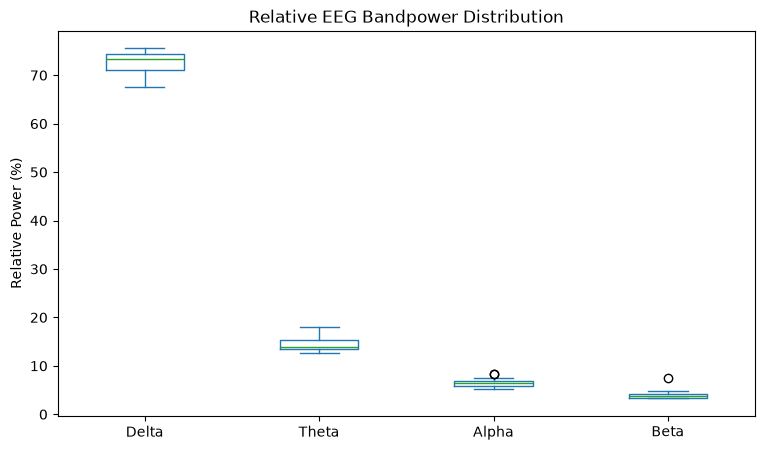

In [52]:
# relative bandpower distribution boxplot for subject

import matplotlib.pyplot as plt

relative_bandpower.plot(
    kind='box',
    figsize=(9, 5),
    ylabel='Relative Power (%)',
    title='Relative EEG Bandpower Distribution'
)

plt.show()

In [81]:
# check for difference in front and posterior channels as expected for resting state, eyes closed EEG

frontal_channels = ['Fp1', 'Fp2', 'F3', 'F4']
posterior_channels = ['O1', 'O2', 'P3', 'P4']

print("Frontal alpha:")
print(relative_bandpower.loc[
    relative_bandpower.index.intersection(frontal_channels),
    'Alpha'
].mean())

print("Posterior alpha:")
print(relative_bandpower.loc[
    relative_bandpower.index.intersection(posterior_channels),
    'Alpha'
].mean())

Frontal alpha:
8.313373496510312
Posterior alpha:
16.144650692957608


In [82]:
# check for alpha peaks

alpha_idx = (freqs >= 8) & (freqs <= 13)

for channel_idx, channel_name in enumerate(psd_ch_names):

    alpha_peak_idx = np.argmax(psds[channel_idx, alpha_idx])

    alpha_freqs = freqs[alpha_idx]

    peak_frequency = alpha_freqs[alpha_peak_idx]

    print(channel_name, peak_frequency)
    

Fp1 8.056640625
Fp2 8.056640625
F3 8.056640625
F4 8.056640625
C3 8.056640625
C4 8.30078125
P3 8.056640625
P4 8.056640625
O1 8.056640625
O2 8.056640625
F7 8.056640625
F8 8.056640625
T3 8.056640625
T4 8.056640625
T5 8.056640625
T6 8.056640625
Fz 8.056640625
Cz 8.056640625
Pz 8.056640625


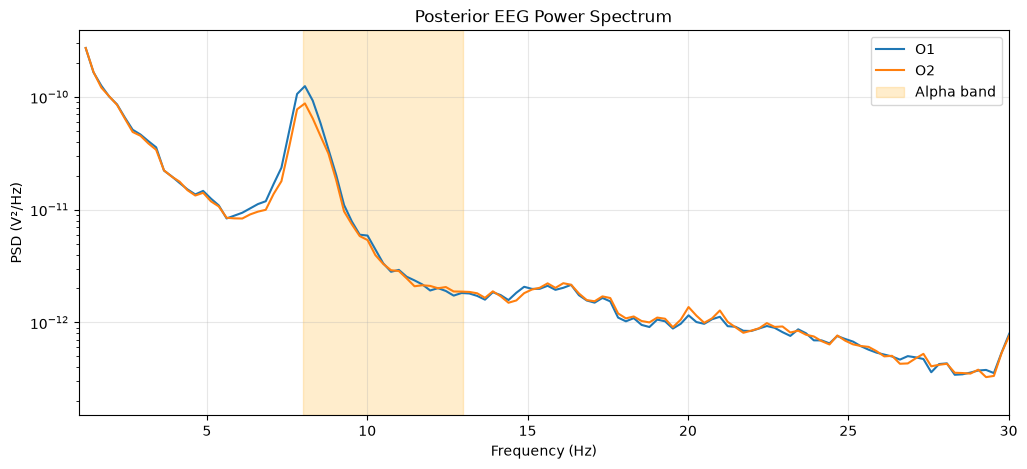

In [83]:
# Plot posterior electrode PSDs -- check for PSD/relative power correctness

posterior_channels = ['O1', 'O2']

plt.figure(figsize=(12, 5))

for channel in posterior_channels:

    if channel in psd_ch_names:

        idx = psd_ch_names.index(channel)

        plt.plot(
            freqs,
            psds[idx],
            label=channel
        )

plt.xlim(1, 30)
plt.yscale('log')

plt.axvspan(8, 13, alpha=0.2, color='orange',
            label='Alpha band')

plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD (V²/Hz)')
plt.title('Posterior EEG Power Spectrum')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [54]:
# starting to put together my full pipeline

import os
import glob

input_folder = [
    folder for folder in os.listdir(data_dir)
    if folder.startswith('sub-')
]

print(input_folder)
    
output_folder = "/hickory/users/m/e/meashe/NSCI270/relative-power-results/"

['sub-001', 'sub-002', 'sub-003', 'sub-004', 'sub-005', 'sub-006', 'sub-007', 'sub-008', 'sub-009', 'sub-010', 'sub-011', 'sub-012', 'sub-013', 'sub-014', 'sub-015', 'sub-016', 'sub-017', 'sub-018', 'sub-019', 'sub-020', 'sub-021', 'sub-022', 'sub-023', 'sub-025', 'sub-026', 'sub-027', 'sub-028', 'sub-029', 'sub-031', 'sub-032', 'sub-033', 'sub-034', 'sub-035', 'sub-036', 'sub-037', 'sub-038', 'sub-039', 'sub-040', 'sub-041', 'sub-042', 'sub-043', 'sub-044', 'sub-045', 'sub-046', 'sub-047', 'sub-048', 'sub-049', 'sub-050', 'sub-051', 'sub-052', 'sub-053', 'sub-054', 'sub-055', 'sub-056', 'sub-057', 'sub-058', 'sub-059', 'sub-060', 'sub-061', 'sub-062', 'sub-063', 'sub-064', 'sub-065', 'sub-066', 'sub-068', 'sub-069', 'sub-070', 'sub-071', 'sub-072', 'sub-073', 'sub-074', 'sub-075', 'sub-076', 'sub-077', 'sub-078', 'sub-079', 'sub-080', 'sub-081', 'sub-082', 'sub-083', 'sub-084', 'sub-085', 'sub-087', 'sub-088']


In [ ]:
files = []

for participant in input_folder:

    participant_path = os.path.join(data_dir, participant)

    participant_files = glob.glob(
        os.path.join(participant_path, "**", "*.set"),
        recursive=True
    )

    files.extend(participant_files)

files = sorted(files)

In [ ]:
for file in files:

    participant_id = os.path.basename(
        os.path.dirname(
            os.path.dirname(file)
        )
    )
   
    print(f"\nProcessing {participant_id}...")

    subject = mne.io.read_raw_eeglab(
        file,
        preload=True
    )

    subject.crop(tmin=100, tmax=600)